In [1]:
import os
os.environ["USE_TF"] = "0"
os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["USE_TORCH"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import json, glob, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE)
print("cwd:", os.getcwd())

torch 2.4.1+cpu | device: cpu
cwd: c:\Users\MR\Documents\RGB_sence_text


In [ ]:
DATA_DIR = "Datasets"
COLOR_COLS = ["r1","g1","b1","r2","g2","b2","r3","g3","b3"]

def load_jsonl(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line.startswith("{"):
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            if isinstance(obj.get("rows"), list): 
                rows.extend(obj["rows"])
            else:
                rows.append(obj)
    return rows

frames = []
for path in sorted(glob.glob(f"{DATA_DIR}/*.jsonl")):
    part = pd.DataFrame(load_jsonl(path))
    part["source"] = os.path.basename(path)
    print(f"{os.path.basename(path):30s} {len(part):5d} rows")
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print("total:", len(df))

Direct_Colors.jsonl              180 rows
Irrelevancies.jsonl              360 rows
Locations_and_Scenes.jsonl       240 rows
Seasons_and_Time.jsonl           480 rows
Senses.jsonl                     420 rows
total: 1680


In [ ]:
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]

df["related"] = np.where(df["source"].str.contains("Irrelevanc", case=False), 0, 1)

for c in COLOR_COLS:
    if c not in df.columns:
        df[c] = np.nan
df[COLOR_COLS] = df[COLOR_COLS].apply(pd.to_numeric, errors="coerce")

bad = (df["related"] == 1) & df[COLOR_COLS].isna().any(axis=1)
print("bad color rows dropped:", bad.sum())
df = df[~bad]

df[COLOR_COLS] = df[COLOR_COLS].clip(0, 255).fillna(0)  
df = df.drop_duplicates(subset="text").reset_index(drop=True)

print(df["related"].value_counts())
print(df.groupby("source").size())

bad color rows dropped: 48
related
1    1272
0     359
Name: count, dtype: int64
source
Direct_Colors.jsonl           180
Irrelevancies.jsonl           359
Locations_and_Scenes.jsonl    240
Seasons_and_Time.jsonl        466
Senses.jsonl                  386
dtype: int64


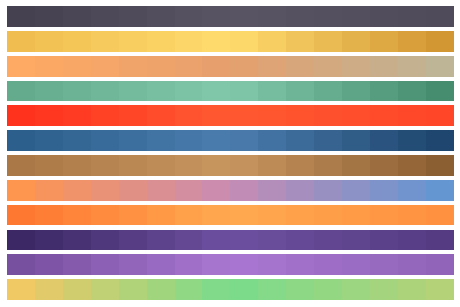

آرزوی یک بار دیگه دیدنت
پرتوهای طلایی خورشید روی خاک خشک
عصر گرم تیرماه و پهن کردن بساط شام تو حیاط
هوای پاک و خنک صبحگاهی در روستا
عشق آتشین و پرشور
باد خنک دریا توی موهام می‌پیچه
کاروانسرای قدیمی وسط مسیر کویری
دلم هوای غروب ساحل و صدای موج کرده
شروع دوباره با عزم راسخ و شجاعت
معمای شهر ارواح و افسانه‌ها
شب پر ستاره و عهد عاشقی
شکوفه‌زدن دوباره بعد از یک زمستان سخت


In [ ]:
def make_strip(c9, n=16):
    c = np.asarray(c9, dtype=float).reshape(3, 3)
    t = np.linspace(0, 1, n)
    return np.stack([np.interp(t, [0, 0.5, 1], c[:, ch]) for ch in range(3)], axis=1)

sample = df[df["related"] == 1].sample(12, random_state=1)
fig, axes = plt.subplots(len(sample), 1, figsize=(8, len(sample) * 0.45))
for ax, (_, r) in zip(axes, sample.iterrows()):
    ax.imshow(make_strip(r[COLOR_COLS].values)[None].astype(np.uint8), aspect="auto")
    ax.axis("off")
plt.show()

for t in sample["text"]:    
    print(t)

In [ ]:
from sentence_transformers import SentenceTransformer

# Load the model from a local folder if it is available:
# embedder = SentenceTransformer("multilingual-e5-small", device=DEVICE)

# Otherwise, download it from Hugging Face on the first run.
embedder = SentenceTransformer("intfloat/multilingual-e5-small", device=DEVICE)

texts = ["query: " + t for t in df["text"]]
EMB = embedder.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=True)

np.save("embeddings.npy", EMB)
print(EMB.shape)  

Batches:   0%|          | 0/26 [00:00<?, ?it/s]

(1631, 384)


In [6]:
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupShuffleSplit

groups = KMeans(n_clusters=200, n_init=3, random_state=SEED).fit_predict(EMB)
train_idx, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
                          .split(EMB, groups=groups))

X     = torch.tensor(EMB, dtype=torch.float32)
Y_rgb = torch.tensor(df[COLOR_COLS].values / 255.0, dtype=torch.float32)
Y_rel = torch.tensor(df["related"].values, dtype=torch.float32)

def make_loader(idx, shuffle):
    ds = TensorDataset(X[idx], Y_rgb[idx], Y_rel[idx])
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

train_dl = make_loader(train_idx, True)
val_dl   = make_loader(val_idx, False)

print("train:", len(train_idx), "| val:", len(val_idx))
print("val related ratio:", Y_rel[val_idx].mean().item())

c:\Users\MR\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\MR\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\MR\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\MR\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 966, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\MR\AppData\Local\Programs\Python\Python310\lib\subprocess.py", lin

train: 1359 | val: 272
val related ratio: 0.7941176295280457


In [ ]:
class MoodNet(nn.Module):
    def __init__(self, in_dim=384, h1=256, h2=128, p=0.2):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(in_dim, h1), nn.GELU(), nn.Dropout(p),
            nn.Linear(h1, h2), nn.GELU(), nn.Dropout(p),
        )
        self.color_head = nn.Linear(h2, 9)
        self.rel_head   = nn.Linear(h2, 1)

    def forward(self, x):
        h = self.body(x)
        rgb   = torch.sigmoid(self.color_head(h))   
        logit = self.rel_head(h).squeeze(-1)       
        return rgb, logit

model = MoodNet().to(DEVICE)
print(sum(p.numel() for p in model.parameters()), "parameters")

132746 parameters


epoch   0 | train 0.9653 | val 0.9129
epoch  10 | train 0.4155 | val 0.4585
epoch  20 | train 0.3027 | val 0.3640
epoch  30 | train 0.2651 | val 0.3528
epoch  40 | train 0.2324 | val 0.3313
epoch  50 | train 0.2069 | val 0.3195
epoch  60 | train 0.1918 | val 0.3331
epoch  70 | train 0.1936 | val 0.3196
epoch  80 | train 0.1792 | val 0.3326
epoch  90 | train 0.1677 | val 0.3308
early stop at epoch 97
best val loss: 0.3169


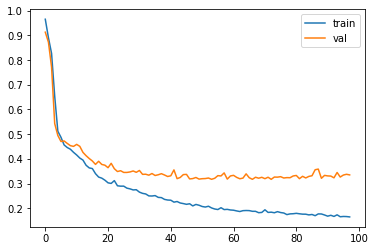

In [48]:
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
bce = nn.BCEWithLogitsLoss()
COLOR_W = 5.0

def compute_loss(rgb, logit, y_rgb, y_rel):
    l_rel = bce(logit, y_rel)
    mse = ((rgb - y_rgb) ** 2).mean(dim=1)
    l_col = (mse * y_rel).sum() / y_rel.sum().clamp(min=1)
    return COLOR_W * l_col + l_rel, l_col, l_rel

best_val, best_state, bad, PATIENCE = 1e9, None, 0, 25
hist = {"train": [], "val": []}

for epoch in range(300):
    model.train()
    tr, n = 0.0, 0
    for xb, yc, yr in train_dl:
        xb, yc, yr = xb.to(DEVICE), yc.to(DEVICE), yr.to(DEVICE)
        rgb, logit = model(xb)
        loss, _, _ = compute_loss(rgb, logit, yc, yr)
        opt.zero_grad(); loss.backward(); opt.step()
        tr += loss.item() * len(xb); n += len(xb)

    model.eval()
    va, m = 0.0, 0
    with torch.no_grad():
        for xb, yc, yr in val_dl:
            xb, yc, yr = xb.to(DEVICE), yc.to(DEVICE), yr.to(DEVICE)
            rgb, logit = model(xb)
            loss, _, _ = compute_loss(rgb, logit, yc, yr)
            va += loss.item() * len(xb); m += len(xb)

    tr, va = tr / n, va / m
    hist["train"].append(tr); hist["val"].append(va)

    if va < best_val:
        best_val, bad = va, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1

    if epoch % 10 == 0:
        print(f"epoch {epoch:3d} | train {tr:.4f} | val {va:.4f}")
    if bad >= PATIENCE:
        print("early stop at epoch", epoch)
        break

model.load_state_dict(best_state)
print("best val loss:", round(best_val, 4))

plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.legend(); plt.show()

In [49]:
model.eval()
with torch.no_grad():
    rgb, logit = model(X[val_idx].to(DEVICE))
rgb = rgb.cpu(); prob = torch.sigmoid(logit).cpu().numpy()
true_rel = Y_rel[val_idx].numpy()

mask = true_rel == 1
mae = (rgb[mask] - Y_rgb[val_idx][mask]).abs().mean().item() * 255
print(f"color MAE on related val rows: {mae:.1f} (از ۲۵۵)")

for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = prob >= thr
    tp = ((pred == 1) & (true_rel == 1)).sum()
    fp = ((pred == 1) & (true_rel == 0)).sum()
    fn = ((pred == 0) & (true_rel == 1)).sum()
    acc  = (pred == true_rel).mean()
    prec = tp / max(tp + fp, 1)
    rec  = tp / max(tp + fn, 1)
    print(f"thr {thr}: acc {acc:.3f} | precision {prec:.3f} | recall {rec:.3f}")

color MAE on related val rows: 47.8 (از ۲۵۵)
thr 0.3: acc 0.993 | precision 0.991 | recall 1.000
thr 0.4: acc 0.993 | precision 0.991 | recall 1.000
thr 0.5: acc 0.993 | precision 0.991 | recall 1.000
thr 0.6: acc 0.993 | precision 0.991 | recall 1.000
thr 0.7: acc 0.989 | precision 0.991 | recall 0.995


In [ ]:
THRESH = 0.5 

torch.save({
    "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
    "in_dim": 384, "h1": 256, "h2": 128,
    "threshold": THRESH,
}, "mood_model.pt")
print("saved mood_model.pt")

saved mood_model.pt


'طلایی ناب و گرم' -> related=True (p=1.00) | colors=[[240, 150, 81], [238, 161, 91], [218, 141, 97]]


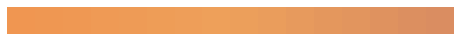

{'related': True,
 'prob': 0.9999938011169434,
 'colors': [[240, 150, 81], [238, 161, 91], [218, 141, 97]]}

In [55]:
NEUTRAL = (255, 200, 140)   

@torch.no_grad()
def predict(text, thr=THRESH, show=True):
    e = embedder.encode(["query: " + text.strip()], normalize_embeddings=True)
    rgb, logit = model(torch.tensor(e, dtype=torch.float32).to(DEVICE))
    p = torch.sigmoid(logit).item()
    colors = (rgb[0].cpu().numpy() * 255).round().astype(int).reshape(3, 3)

    related = p >= thr
    if not related:
        colors = np.array([NEUTRAL] * 3)

    if show:
        print(f"{text!r} -> related={related} (p={p:.2f}) | colors={colors.tolist()}")
        plt.figure(figsize=(8, 0.5))
        plt.imshow(make_strip(colors)[None].astype(np.uint8), aspect="auto")
        plt.axis("off"); plt.show()
    return {"related": bool(related), "prob": p, "colors": colors.tolist()}

txt = "طلایی ناب و گرم"
predict(txt)